# Preparation

In [ ]:
# Mount Google Drive

# Core Libraries
import os
import copy
import numpy as np
import pandas as pd
from math import floor
from PIL import Image
import matplotlib.pyplot as plt

# PyTorch and TorchVision
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import random

# Diffusion
from diffusers import UNet2DModel, DDPMScheduler

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if using multi-GPU
    np.random.seed(seed)
    random.seed(seed)

    # Ensures deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(11)

# Data Paths
DATA_DIR = os.environ.get("BISCUIT_DATA_DIR", "../../data/DS")  # built by 00_data_prep/prepare_data.py --mode ok_nok
print(DATA_DIR)

trainPath = os.path.join(DATA_DIR, 'train')
testPath = os.path.join(DATA_DIR, 'test')
valPath = os.path.join(DATA_DIR, 'valid')


# Dataset

In [ ]:
from torchvision import datasets, transforms

IMG_SIZE = 128

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),                    # <- converts PIL -> Tensor
    transforms.Normalize([0.5]*3, [0.5]*3),   # [-1, 1] for DDPM
])

train_dataset = datasets.ImageFolder(root=trainPath, transform=transform)
valid_dataset = datasets.ImageFolder(root=valPath,  transform=transform)
test_dataset  = datasets.ImageFolder(root=testPath,  transform=transform)

batch_size = 10
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,        # also shuffle for training
    num_workers=4,
    pin_memory=True,
)
valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Diffusion

## Load Pretrained Model

In [ ]:
model_id = "google/ddpm-cifar10-32"

unet = UNet2DModel.from_pretrained(model_id).to(device)
noise_scheduler = DDPMScheduler.from_pretrained(model_id)

In [ ]:
unet.config

FrozenDict([('sample_size', 32),
            ('in_channels', 3),
            ('out_channels', 3),
            ('center_input_sample', False),
            ('time_embedding_type', 'positional'),
            ('time_embedding_dim', None),
            ('freq_shift', 1),
            ('flip_sin_to_cos', False),
            ('down_block_types',
             ['DownBlock2D', 'AttnDownBlock2D', 'DownBlock2D', 'DownBlock2D']),
            ('mid_block_type', 'UNetMidBlock2D'),
            ('up_block_types',
             ['UpBlock2D', 'UpBlock2D', 'AttnUpBlock2D', 'UpBlock2D']),
            ('block_out_channels', [128, 256, 256, 256]),
            ('layers_per_block', 2),
            ('mid_block_scale_factor', 1),
            ('downsample_padding', 0),
            ('downsample_type', 'conv'),
            ('upsample_type', 'conv'),
            ('dropout', 0.0),
            ('act_fn', 'silu'),
            ('attention_head_dim', None),
            ('norm_num_groups', 32),
            ('attn_norm_num_gr

## Effect of the Pretrained Model's reconstruction


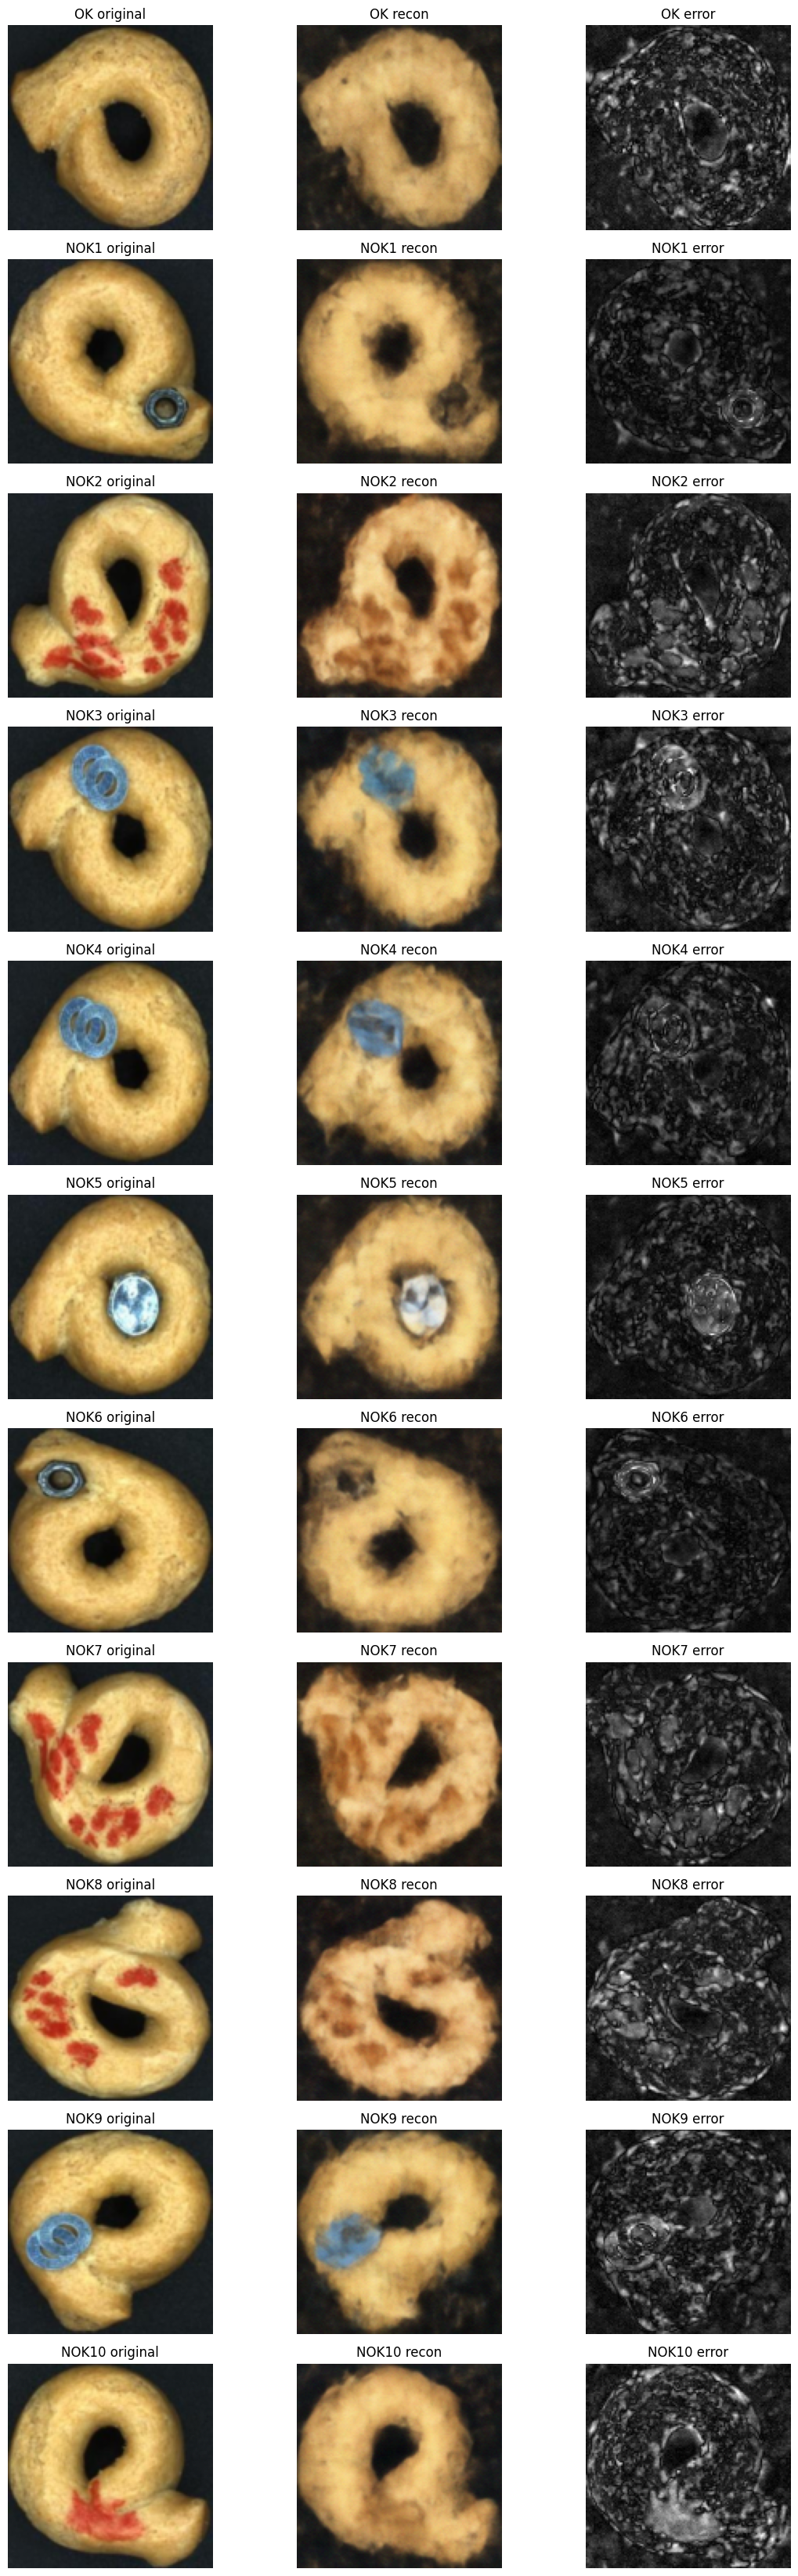

In [ ]:
import matplotlib.pyplot as plt
import torch
import random

unet.eval()

# ------------------------------------------------------
# Config: how many NOK samples to show
# ------------------------------------------------------
NUM_NOK = 10  # change this to whatever you want


# ------------------------------------------------------
# Helper: undo normalization to show real RGB images
# ------------------------------------------------------
def denormalize(img_tensor):
    return img_tensor * 0.5 + 0.5  # [-1,1] → [0,1]


# ------------------------------------------------------
# 1-step DDPM reconstruction (unchanged)
# ------------------------------------------------------
@torch.no_grad()
def reconstruct_once(x, t_eval=300):
    x = x.to(device)
    B = x.shape[0]

    t = torch.full((B,), t_eval, device=device, dtype=torch.long)

    noise = torch.randn_like(x)
    x_t = noise_scheduler.add_noise(x, noise, t)

    noise_pred = unet(x_t, t).sample

    alphas_cumprod = noise_scheduler.alphas_cumprod.to(device)
    alpha_bar_t = alphas_cumprod[t].view(-1, 1, 1, 1)
    sigma_t = (1 - alpha_bar_t).sqrt()

    x0_hat = (x_t - sigma_t * noise_pred) / alpha_bar_t.sqrt()
    return x0_hat.clamp(-1, 1)


# ------------------------------------------------------
# Randomly sample 1 OK and N NOK from val set
# ------------------------------------------------------
ok_idx  = valid_dataset.class_to_idx["ok"]
nok_idx = valid_dataset.class_to_idx["nok"]

ok_indices  = [i for i, y in enumerate(valid_dataset.targets) if y == ok_idx]
nok_indices = [i for i, y in enumerate(valid_dataset.targets) if y == nok_idx]

if len(ok_indices) == 0:
    raise ValueError("No OK samples in valid_dataset.")
if len(nok_indices) == 0:
    raise ValueError("No NOK samples in valid_dataset.")

chosen_ok_idx = random.choice(ok_indices)

num_nok_to_pick = min(NUM_NOK, len(nok_indices))
chosen_nok_idx = random.sample(nok_indices, k=num_nok_to_pick)

ok_sample = valid_dataset[chosen_ok_idx][0]  # [3,H,W]
nok_samples = [valid_dataset[i][0] for i in chosen_nok_idx]

imgs = [ok_sample] + nok_samples                  # list length = 1 + num_nok_to_pick
imgs_batch = torch.stack(imgs, dim=0)             # [1+N,3,H,W]

recons = reconstruct_once(imgs_batch).cpu()       # same shape


# ------------------------------------------------------
# Plot ((1+N) rows × 3 columns: orig, recon, error heatmap)
# ------------------------------------------------------
n_rows = 1 + num_nok_to_pick
fig, axes = plt.subplots(n_rows, 3, figsize=(12, 3 * n_rows))

titles = ["OK original", "OK recon", "OK error"]
for i in range(num_nok_to_pick):
    titles.append(f"NOK{i+1} original")
    titles.append(f"NOK{i+1} recon")
    titles.append(f"NOK{i+1} error")

for i in range(n_rows):
    # original and recon in [0,1]
    orig_vis = denormalize(imgs[i]).permute(1, 2, 0)      # [H,W,3]
    recon_vis = denormalize(recons[i]).permute(1, 2, 0)   # [H,W,3]

    # per pixel error (mean over channels, so [H,W])
    error_map = (orig_vis - recon_vis).abs().mean(dim=2)

    # original
    axes[i, 0].imshow(orig_vis)
    axes[i, 0].set_title(titles[3 * i])
    axes[i, 0].axis("off")

    # reconstructed
    axes[i, 1].imshow(recon_vis)
    axes[i, 1].set_title(titles[3 * i + 1])
    axes[i, 1].axis("off")

    # error heatmap
    im = axes[i, 2].imshow(error_map, cmap="gray")
    axes[i, 2].set_title(titles[3 * i + 2])
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()


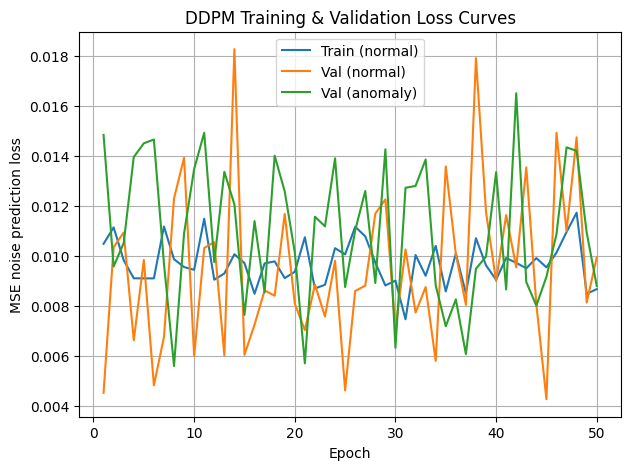

Epoch 50/50 | Train: 0.0087 | Val(normal): 0.0099 | Val(anom): 0.0088 | No improve: 5/20


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output

# ============================================================
# CLASS INDEX FIX
# ============================================================

# train set only has "ok"
train_normal_idx = train_dataset.class_to_idx["ok"]
print("Train normal idx:", train_normal_idx)

# val set has both "ok" and "nok"
val_normal_idx = valid_dataset.class_to_idx["ok"]
val_anom_idx   = valid_dataset.class_to_idx["nok"]
print("Val normal idx:", val_normal_idx)
print("Val anomaly idx:", val_anom_idx)


# ============================================================
# TRAINING LOOP
# ============================================================

num_epochs = 100
patience = 20  # early stopping patience
optimizer = torch.optim.AdamW(unet.parameters(), lr=1e-5)

train_losses = []
val_normal_losses = []
val_anom_losses = []

best_val_normal = float("inf")
epochs_no_improve = 0

for epoch in range(num_epochs):
    print(epoch)

    # =========================
    # TRAIN (only normal)
    # =========================
    unet.train()
    running_train_loss = 0.0
    n_train_batches = 0
    for x, y in train_loader:   # all y == train_normal_idx
        x = x.to(device)

        noise = torch.randn_like(x)

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (x.shape[0],),
            device=device,
            dtype=torch.long
        )

        noisy_x = noise_scheduler.add_noise(x, noise, timesteps)
        noise_pred = unet(noisy_x, timesteps).sample

        loss = F.mse_loss(noise_pred, noise)

        optimizer.zero_grad()

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()
        n_train_batches += 1

    avg_train_loss = running_train_loss / max(1, n_train_batches)
    train_losses.append(avg_train_loss)


    # =========================
    # VALIDATION
    # =========================
    unet.eval()
    running_val_normal = 0.0
    running_val_anom   = 0.0
    n_val_normal = 0
    n_val_anom   = 0

    with torch.no_grad():
        for x_val, y_val in valid_loader:
            x_val = x_val.to(device)
            y_val = y_val.to(device)

            noise = torch.randn_like(x_val)

            timesteps = torch.randint(
                0,
                noise_scheduler.config.num_train_timesteps,
                (x_val.shape[0],),
                device=device,
                dtype=torch.long
            )

            noisy_x_val = noise_scheduler.add_noise(x_val, noise, timesteps)
            noise_pred_val = unet(noisy_x_val, timesteps).sample

            loss_per_sample = F.mse_loss(
                noise_pred_val, noise, reduction="none"
            ).mean(dim=[1, 2, 3])  # [B]

            # === Corrected masks ===
            normal_mask = (y_val == val_normal_idx)
            anom_mask   = (y_val == val_anom_idx)

            if normal_mask.any():
                running_val_normal += loss_per_sample[normal_mask].sum().item()
                n_val_normal += normal_mask.sum().item()

            if anom_mask.any():
                running_val_anom += loss_per_sample[anom_mask].sum().item()
                n_val_anom += anom_mask.sum().item()

    avg_val_normal = running_val_normal / max(1, n_val_normal)
    avg_val_anom   = running_val_anom   / max(1, n_val_anom)

    val_normal_losses.append(avg_val_normal)
    val_anom_losses.append(avg_val_anom)


    # =========================
    # EARLY STOPPING (based on val normal)
    # =========================
    if avg_val_normal < best_val_normal:
        best_val_normal = avg_val_normal
        epochs_no_improve = 0
        best_state = {
            "unet": unet.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": epoch,
            "best_val_normal": best_val_normal,
        }
    else:
        epochs_no_improve += 1


    # =========================
    # LIVE PLOT
    # =========================
    clear_output(wait=True)
    plt.figure(figsize=(7, 5))
    epochs_range = range(1, len(train_losses) + 1)

    plt.plot(epochs_range, train_losses,        label="Train (normal)")
    plt.plot(epochs_range, val_normal_losses,   label="Val (normal)")
    plt.plot(epochs_range, val_anom_losses,     label="Val (anomaly)")

    plt.xlabel("Epoch")
    plt.ylabel("MSE noise prediction loss")
    plt.title("DDPM Training & Validation Loss Curves")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train: {avg_train_loss:.4f} | "
        f"Val(normal): {avg_val_normal:.4f} | "
        f"Val(anom): {avg_val_anom:.4f} | "
        f"No improve: {epochs_no_improve}/{patience}"
    )

    # if epochs_no_improve >= patience:
    #     print("Early stopping triggered.")
    #     break


# =========================
# Restore best model
# =========================
# unet.load_state_dict(best_state["unet"])
# print("Restored best model from epoch", best_state["epoch"] + 1)


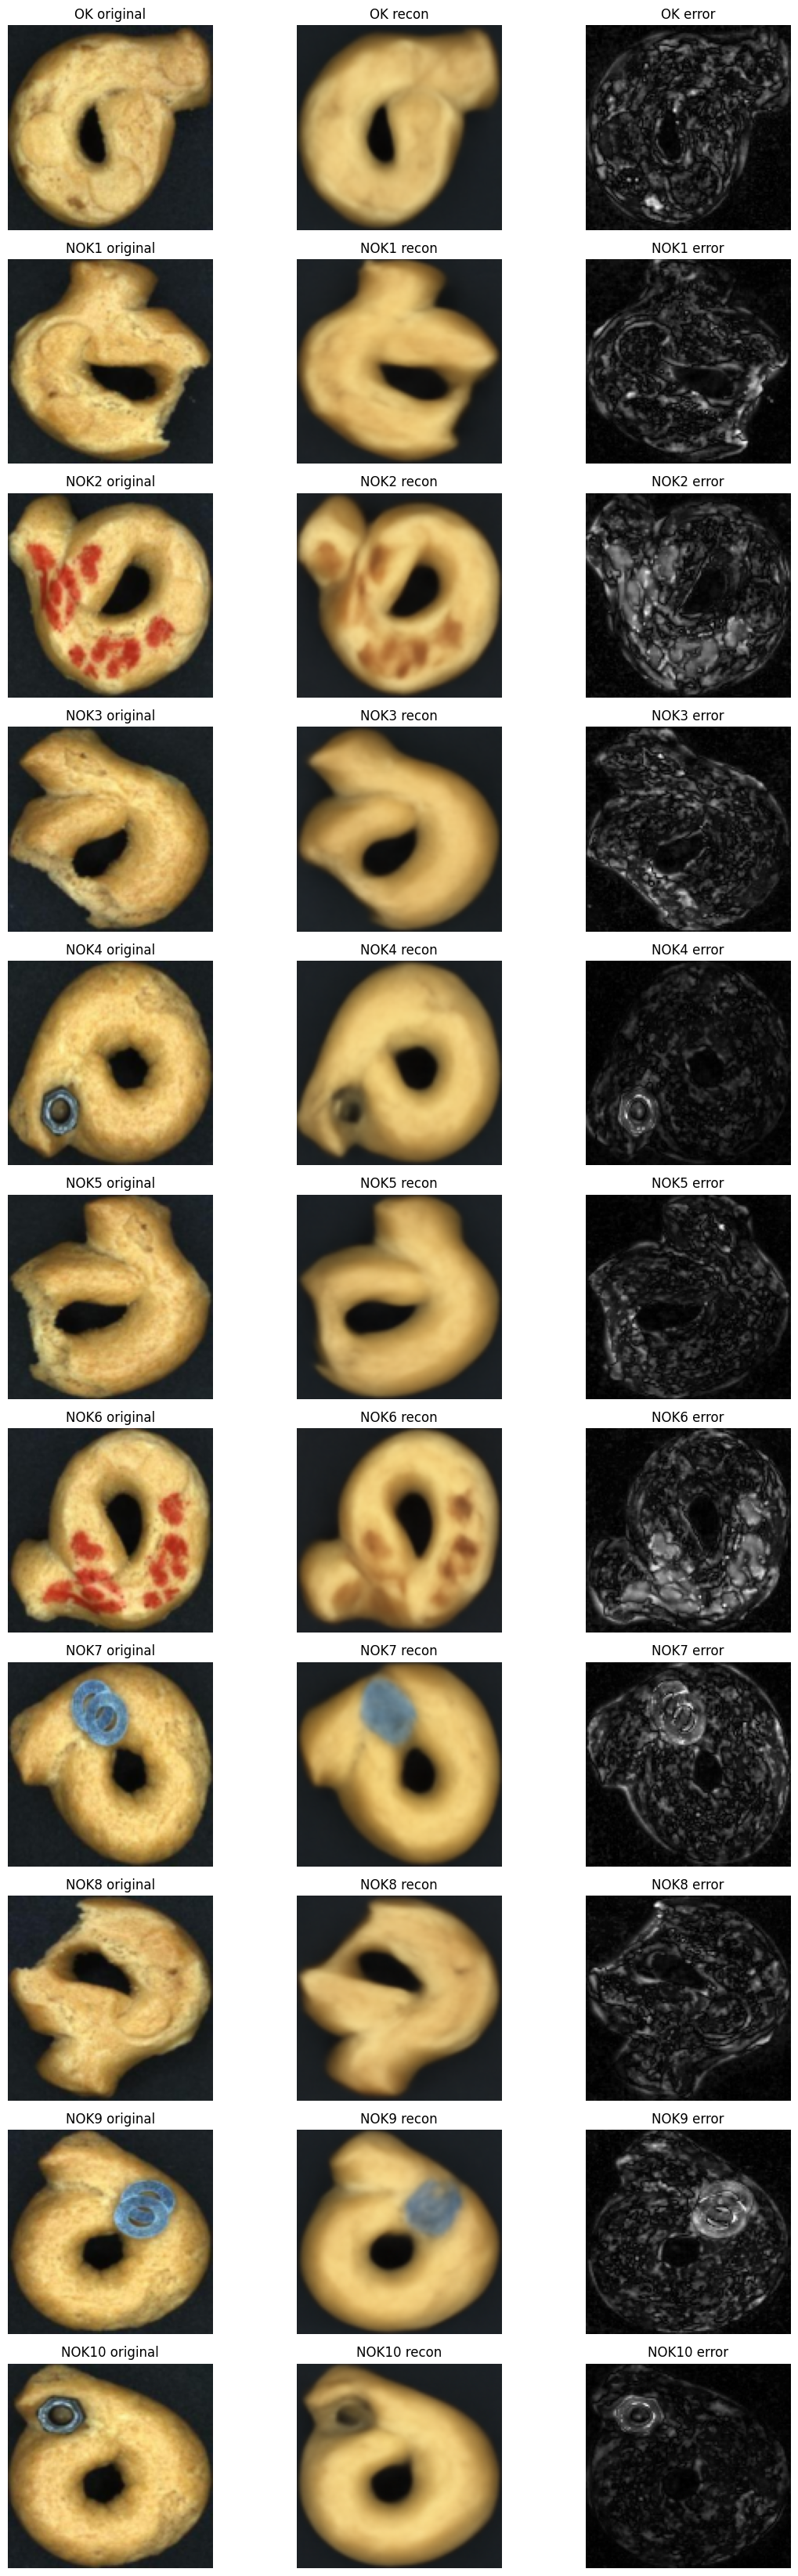

In [ ]:
import matplotlib.pyplot as plt
import torch
import random

unet.eval()

# ------------------------------------------------------
# Config: how many NOK samples to show
# ------------------------------------------------------
NUM_NOK = 10  # change this to whatever you want


# ------------------------------------------------------
# Helper: undo normalization to show real RGB images
# ------------------------------------------------------
def denormalize(img_tensor):
    return img_tensor * 0.5 + 0.5  # [-1,1] → [0,1]


# ------------------------------------------------------
# 1-step DDPM reconstruction (unchanged)
# ------------------------------------------------------
@torch.no_grad()
def reconstruct_once(x, t_eval=300):
    x = x.to(device)
    B = x.shape[0]

    t = torch.full((B,), t_eval, device=device, dtype=torch.long)

    noise = torch.randn_like(x)
    x_t = noise_scheduler.add_noise(x, noise, t)

    noise_pred = unet(x_t, t).sample

    alphas_cumprod = noise_scheduler.alphas_cumprod.to(device)
    alpha_bar_t = alphas_cumprod[t].view(-1, 1, 1, 1)
    sigma_t = (1 - alpha_bar_t).sqrt()

    x0_hat = (x_t - sigma_t * noise_pred) / alpha_bar_t.sqrt()
    return x0_hat.clamp(-1, 1)


# ------------------------------------------------------
# Randomly sample 1 OK and N NOK from val set
# ------------------------------------------------------
ok_idx  = valid_dataset.class_to_idx["ok"]
nok_idx = valid_dataset.class_to_idx["nok"]

ok_indices  = [i for i, y in enumerate(valid_dataset.targets) if y == ok_idx]
nok_indices = [i for i, y in enumerate(valid_dataset.targets) if y == nok_idx]

if len(ok_indices) == 0:
    raise ValueError("No OK samples in valid_dataset.")
if len(nok_indices) == 0:
    raise ValueError("No NOK samples in valid_dataset.")

chosen_ok_idx = random.choice(ok_indices)

num_nok_to_pick = min(NUM_NOK, len(nok_indices))
chosen_nok_idx = random.sample(nok_indices, k=num_nok_to_pick)

ok_sample = valid_dataset[chosen_ok_idx][0]  # [3,H,W]
nok_samples = [valid_dataset[i][0] for i in chosen_nok_idx]

imgs = [ok_sample] + nok_samples                  # list length = 1 + num_nok_to_pick
imgs_batch = torch.stack(imgs, dim=0)             # [1+N,3,H,W]

recons = reconstruct_once(imgs_batch).cpu()       # same shape


# ------------------------------------------------------
# Plot ((1+N) rows × 3 columns: orig, recon, error heatmap)
# ------------------------------------------------------
n_rows = 1 + num_nok_to_pick
fig, axes = plt.subplots(n_rows, 3, figsize=(12, 3 * n_rows))

titles = ["OK original", "OK recon", "OK error"]
for i in range(num_nok_to_pick):
    titles.append(f"NOK{i+1} original")
    titles.append(f"NOK{i+1} recon")
    titles.append(f"NOK{i+1} error")

for i in range(n_rows):
    # original and recon in [0,1]
    orig_vis = denormalize(imgs[i]).permute(1, 2, 0)      # [H,W,3]
    recon_vis = denormalize(recons[i]).permute(1, 2, 0)   # [H,W,3]

    # per pixel error (mean over channels, so [H,W])
    error_map = (orig_vis - recon_vis).abs().mean(dim=2)

    # original
    axes[i, 0].imshow(orig_vis)
    axes[i, 0].set_title(titles[3 * i])
    axes[i, 0].axis("off")

    # reconstructed
    axes[i, 1].imshow(recon_vis)
    axes[i, 1].set_title(titles[3 * i + 1])
    axes[i, 1].axis("off")

    # error heatmap
    im = axes[i, 2].imshow(error_map, cmap="gray")
    axes[i, 2].set_title(titles[3 * i + 2])
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
model_path = "models"
os.makedirs(model_path, exist_ok=True)

In [ ]:
import os
import torch

os.makedirs(model_path, exist_ok=True)

checkpoint = {
    # model + optimizer
    "unet_state": unet.state_dict(),
    "optimizer_state": optimizer.state_dict(),

    # noise scheduler → only config since it has no weights
    "scheduler_state": noise_scheduler.config,

    # training metadata
    "epoch": epoch,
    "best_val_normal": best_val_normal,
    "train_losses": train_losses,
    "val_normal_losses": val_normal_losses,
    "val_anom_losses": val_anom_losses,

    # architecture identity
    "model_id": model_id,           # e.g. "google/ddpm-cifar10-32"
}

torch.save(checkpoint, os.path.join(model_path, "checkpoint.pt"))
print("Saved full checkpoint at:", model_path)


Saved full checkpoint at: /content/drive/Shareddrives/CV_Project/diffusion


In [ ]:
torch.save(unet.state_dict(), os.path.join(model_path, "unet_last.pt"))
torch.save(best_state["unet"], os.path.join(model_path, "unet_best.pt"))